In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [2]:
from pathlib import Path

# Load customer churn dataset
dataset_path = Path.cwd().parent / "Datasets" / "churn-bigml-80.csv"

df = pd.read_csv(dataset_path)

# Display first five rows
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (2666, 20)

Column names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes    

In [2]:
from pathlib import Path
import pandas as pd

dataset_path = Path.cwd().parent / "Datasets" / "churn-bigml-80.csv"

df = pd.read_csv(dataset_path)

df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
# Separate input features and target variable
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2666, 19)
Target shape: (2666,)


In [4]:
# Identify categorical and numerical columns
categorical_columns = X.select_dtypes(include=["str"]).columns.tolist()
numerical_columns = X.select_dtypes(exclude=["str"]).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)

Categorical columns: ['State', 'International plan', 'Voice mail plan']

Numerical columns: ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2132, 19)
Testing data: (534, 19)


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [10]:
# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Create SVM pipeline with Linear Kernel
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear", probability=True, random_state=42))
    ]
)

print("Linear SVM model created successfully!")

Linear SVM model created successfully!


In [12]:
# Train Linear SVM
linear_svm.fit(X_train, y_train)

print("Linear SVM model trained successfully!")

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Linear SVM model trained successfully!


In [13]:
# Predict customer churn
y_pred_linear = linear_svm.predict(X_test)

print("First 10 actual values:")
print(y_test[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_linear[:10].tolist())

First 10 actual values:
[False, False, False, False, False, False, False, False, False, False]

First 10 predicted values:
[False, False, False, False, False, False, False, False, False, False]


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [16]:
print("Linear SVM Performance")
print("----------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_linear))
print("Precision:", precision_score(y_test, y_pred_linear))
print("Recall:", recall_score(y_test, y_pred_linear))
print("F1 Score:", f1_score(y_test, y_pred_linear))

Linear SVM Performance
----------------------
Accuracy: 0.846441947565543
Precision: 0.4166666666666667
Recall: 0.1282051282051282
F1 Score: 0.19607843137254902


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

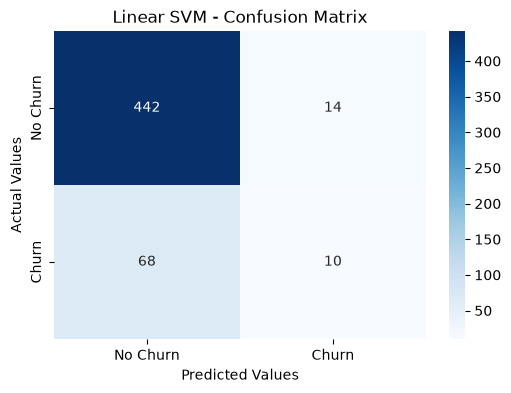

In [19]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Linear SVM - Confusion Matrix")
plt.show()

In [20]:
# Display classification report
print(classification_report(y_test, y_pred_linear))

              precision    recall  f1-score   support

       False       0.87      0.97      0.92       456
        True       0.42      0.13      0.20        78

    accuracy                           0.85       534
   macro avg       0.64      0.55      0.56       534
weighted avg       0.80      0.85      0.81       534



In [21]:
# Create SVM pipeline with RBF Kernel
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=42))
    ]
)

print("RBF SVM model created successfully!")

RBF SVM model created successfully!


In [22]:
# Train RBF SVM
rbf_svm.fit(X_train, y_train)

print("RBF SVM model trained successfully!")

C:\Users\hp\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RBF SVM model trained successfully!


In [23]:
# Predict customer churn using RBF SVM
y_pred_rbf = rbf_svm.predict(X_test)

print("First 10 actual values:")
print(y_test[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred_rbf[:10].tolist())

First 10 actual values:
[False, False, False, False, False, False, False, False, False, False]

First 10 predicted values:
[False, False, False, False, False, False, False, False, False, False]


In [24]:
# Evaluate RBF SVM
print("RBF SVM Performance")
print("-------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rbf))
print("Precision:", precision_score(y_test, y_pred_rbf))
print("Recall:", recall_score(y_test, y_pred_rbf))
print("F1 Score:", f1_score(y_test, y_pred_rbf))

RBF SVM Performance
-------------------
Accuracy: 0.897003745318352
Precision: 0.8108108108108109
Recall: 0.38461538461538464
F1 Score: 0.5217391304347826


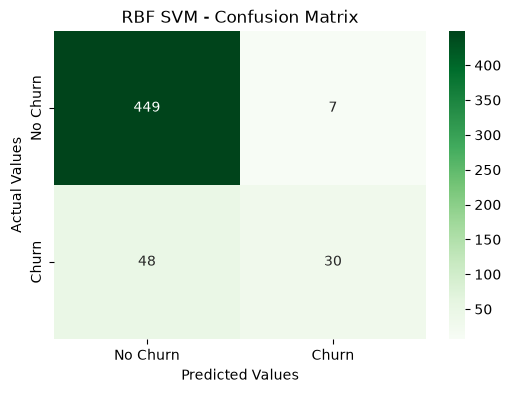

In [25]:
# Generate confusion matrix for RBF SVM
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("RBF SVM - Confusion Matrix")
plt.show()

In [26]:
# Display RBF SVM classification report
print(classification_report(y_test, y_pred_rbf))

              precision    recall  f1-score   support

       False       0.90      0.98      0.94       456
        True       0.81      0.38      0.52        78

    accuracy                           0.90       534
   macro avg       0.86      0.68      0.73       534
weighted avg       0.89      0.90      0.88       534



In [27]:
# Get probability predictions for both models
y_prob_linear = linear_svm.predict_proba(X_test)[:, 1]
y_prob_rbf = rbf_svm.predict_proba(X_test)[:, 1]

# Calculate ROC curves
fpr_linear, tpr_linear, _ = roc_curve(y_test, y_prob_linear)
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, y_prob_rbf)

# Calculate AUC scores
auc_linear = roc_auc_score(y_test, y_prob_linear)
auc_rbf = roc_auc_score(y_test, y_prob_rbf)

print("Linear SVM AUC:", auc_linear)
print("RBF SVM AUC:", auc_rbf)

Linear SVM AUC: 0.7327091767881241
RBF SVM AUC: 0.8638663967611336


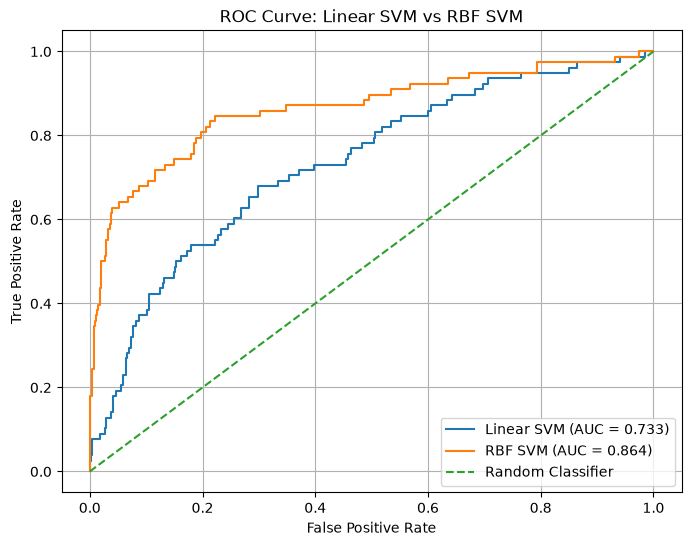

In [28]:
# Plot ROC curves for both kernels
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_linear,
    tpr_linear,
    label=f"Linear SVM (AUC = {auc_linear:.3f})"
)

plt.plot(
    fpr_rbf,
    tpr_rbf,
    label=f"RBF SVM (AUC = {auc_rbf:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Linear SVM vs RBF SVM")
plt.legend()
plt.grid()
plt.show()

In [29]:
# Compare both SVM models
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"],
    "Linear SVM": [
        accuracy_score(y_test, y_pred_linear),
        precision_score(y_test, y_pred_linear),
        recall_score(y_test, y_pred_linear),
        f1_score(y_test, y_pred_linear),
        auc_linear
    ],
    "RBF SVM": [
        accuracy_score(y_test, y_pred_rbf),
        precision_score(y_test, y_pred_rbf),
        recall_score(y_test, y_pred_rbf),
        f1_score(y_test, y_pred_rbf),
        auc_rbf
    ]
})

comparison

,Metric,Linear SVM,RBF SVM
0,Accuracy,0.846442,0.897004
1,Precision,0.416667,0.810811
2,Recall,0.128205,0.384615
3,F1 Score,0.196078,0.521739
4,AUC,0.732709,0.863866


In [30]:
print("SVM CLASSIFICATION - FINAL SUMMARY")
print("----------------------------------")

print("\nLinear SVM AUC:", round(auc_linear, 4))
print("RBF SVM AUC:", round(auc_rbf, 4))

print("\nBest Kernel based on F1 Score:")

if f1_score(y_test, y_pred_linear) > f1_score(y_test, y_pred_rbf):
    print("Linear Kernel")
elif f1_score(y_test, y_pred_rbf) > f1_score(y_test, y_pred_linear):
    print("RBF Kernel")
else:
    print("Both kernels have equal F1 scores")

print("\nPerformance Comparison:")
print(comparison.to_string(index=False))

SVM CLASSIFICATION - FINAL SUMMARY
----------------------------------

Linear SVM AUC: 0.7327
RBF SVM AUC: 0.8639

Best Kernel based on F1 Score:
RBF Kernel

Performance Comparison:
   Metric  Linear SVM  RBF SVM
 Accuracy    0.846442 0.897004
Precision    0.416667 0.810811
   Recall    0.128205 0.384615
 F1 Score    0.196078 0.521739
      AUC    0.732709 0.863866


## Conclusion

In this task, I implemented Support Vector Machine (SVM) classification to predict customer churn using Python and Scikit-learn.

The following steps were performed:

1. Loaded and explored the customer churn dataset.
2. Separated input features and the target variable.
3. Identified numerical and categorical features.
4. Split the dataset into training and testing sets.
5. Applied StandardScaler to numerical features and One-Hot Encoding to categorical features.
6. Built and trained two SVM models using Linear and RBF kernels.
7. Evaluated both models using accuracy, precision, recall, F1-score, confusion matrix, and classification report.
8. Calculated and visualized ROC curves and AUC scores.
9. Compared the performance of Linear and RBF kernels.

This task helped me understand Support Vector Machines, kernel functions, feature scaling, classification evaluation, and the importance of selecting suitable kernels for machine learning problems.

In [31]:
# Select two features for visualizing the decision boundary
features = ["Total day minutes", "Customer service calls"]

X_2d = df[features]
y_2d = df["Churn"]

print("Selected features:", features)
print("Feature shape:", X_2d.shape)

Selected features: ['Total day minutes', 'Customer service calls']
Feature shape: (2666, 2)


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Split the selected data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Train Linear SVM
linear_svm_2d = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)
linear_svm_2d.fit(X_train_2d, y_train_2d)

# Train RBF SVM
rbf_svm_2d = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
rbf_svm_2d.fit(X_train_2d, y_train_2d)

print("Both SVM models trained successfully!")

Both SVM models trained successfully!


In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Create a grid of values
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Combine grid points
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features
)

print("Decision-boundary grid created:", grid.shape)

Decision-boundary grid created: (40000, 2)


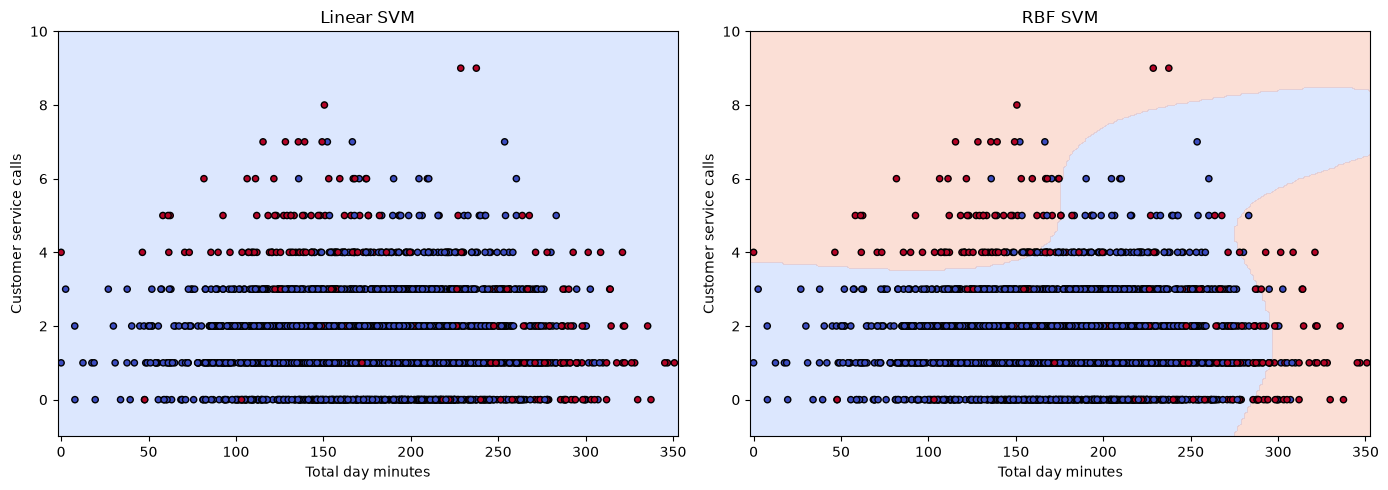

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (linear_svm_2d, "Linear SVM"),
    (rbf_svm_2d, "RBF SVM")
]

for ax, (model, title) in zip(axes, models):

    # Predict classes for every grid point
    predictions = model.predict(grid).reshape(xx.shape)

    # Draw decision regions
    ax.contourf(xx, yy, predictions, alpha=0.3, cmap="coolwarm")

    # Plot actual customer data
    ax.scatter(
        X_2d.iloc[:, 0],
        X_2d.iloc[:, 1],
        c=y_2d.astype(int),
        cmap="coolwarm",
        edgecolors="black",
        s=20
    )

    ax.set_title(title)
    ax.set_xlabel("Total day minutes")
    ax.set_ylabel("Customer service calls")

plt.tight_layout()
plt.show()

### Decision Boundary Visualization

The above graphs show how Linear SVM and RBF SVM classify customers using two selected features: Total day minutes and Customer service calls.

- Linear SVM creates a straight decision boundary to separate the two classes.
- RBF SVM creates a flexible, non-linear decision boundary that can capture more complex patterns.

The background regions represent the predicted classes, while the coloured points represent actual customer observations.

This visualization helps us understand the difference between linear and non-linear SVM classification.